In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [5]:
os.listdir()

['tokenized_access_logs.csv',
 'Supply_Chain_Logistics_Analysis.ipynb',
 'DataCoSupplyChainDataset.csv',
 'DescriptionDataCoSupplyChain.csv']

In [6]:
df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin1")

description = pd.read_csv("DescriptionDataCoSupplyChain.csv", encoding="latin1")

logs = pd.read_csv("tokenized_access_logs.csv", encoding="latin1")

## CHECKING WHETHER THE FILES LOADED SUCCESSFULLY

In [7]:
print("Main Dataset:", df.shape)
print("Description Dataset:", description.shape)
print("Access Logs:", logs.shape)

Main Dataset: (180519, 53)
Description Dataset: (52, 2)
Access Logs: (469977, 8)


# ALL COLUMNS NAMES IN THE MAIN DATASET

In [10]:
df.columns.tolist()

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Id',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'Order Customer Id',
 'order date (DateOrders)',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Image',
 'Product Name',
 'Product P

In [11]:
description.head(15)

,FIELDS,DESCRIPTION
0,Type,: Type of transaction made
1,Days for shipping (real),: Actual shipping days of the purchased product
2,Days for shipment (scheduled),: Days of scheduled delivery of the purchased...
3,Benefit per order,: Earnings per order placed
4,Sales per customer,: Total sales per customer made per customer
5,Delivery Status,: Delivery status of orders: Advance shipping...
6,Late_delivery_risk,: Categorical variable that indicates if send...
7,Category Id,: Product category code
8,Category Name,: Description of the product category
9,Customer City,: City where the customer made the purchase


In [12]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

# CHECK MISSING VALUES ACROSS ALL COLUMNS 

In [14]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519
dtype: int64

# CHECK DUPLICATE RECORDS

In [15]:
df.duplicated().sum()

np.int64(0)

# CHECK THE DATE COLUMNS

In [16]:
print(df[['order date (DateOrders)', 'shipping date (DateOrders)']].head())

  order date (DateOrders) shipping date (DateOrders)
0         1/31/2018 22:56             2/3/2018 22:56
1         1/13/2018 12:27            1/18/2018 12:27
2         1/13/2018 12:06            1/17/2018 12:06
3         1/13/2018 11:45            1/16/2018 11:45
4         1/13/2018 11:24            1/15/2018 11:24


# CONVERT THEM FROM TEXT INTO PROPER DATETIME FORMAT

In [17]:
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'])
df['shipping date (DateOrders)'] = pd.to_datetime(df['shipping date (DateOrders)'])

In [18]:
df[['order date (DateOrders)', 'shipping date (DateOrders)']].dtypes

order date (DateOrders)       datetime64[ns]
shipping date (DateOrders)    datetime64[ns]
dtype: object

# CALCULATE SHIPPING DURATION

In [19]:
df['Order to Shipping Days'] = (
    df['shipping date (DateOrders)'] - df['order date (DateOrders)']
).dt.days

In [20]:
df[['order date (DateOrders)', 'shipping date (DateOrders)', 'Order to Shipping Days']].head()

,order date (DateOrders),shipping date (DateOrders),Order to Shipping Days
0,2018-01-31 22:56:00,2018-02-03 22:56:00,3
1,2018-01-13 12:27:00,2018-01-18 12:27:00,5
2,2018-01-13 12:06:00,2018-01-17 12:06:00,4
3,2018-01-13 11:45:00,2018-01-16 11:45:00,3
4,2018-01-13 11:24:00,2018-01-15 11:24:00,2


# COMPARING ACTUAL SHIPPING TIME WITH SCHEDULED SHIPPING TIME 

In [21]:
df['Shipping Delay'] = (
    df['Days for shipping (real)'] -
    df['Days for shipment (scheduled)']
)

In [22]:
df[['Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Shipping Delay']].head()

,Days for shipping (real),Days for shipment (scheduled),Shipping Delay
0,3,4,-1
1,5,4,1
2,4,4,0
3,3,4,-1
4,2,4,-2


* Positive value = shipment took longer than scheduled.
* Zero = shipment met the schedule.
* Negative value = shipment arrived earlier than scheduled.

# IDENTIFY DELAYED SHIPMENTS

In [23]:
df['Shipping Performance'] = np.where(
    df['Shipping Delay'] > 0, 'Delayed',
    np.where(df['Shipping Delay'] == 0, 'On Time', 'Early')
)

df['Shipping Performance'].value_counts()

Shipping Performance
Delayed    103400
Early       43366
On Time     33753
Name: count, dtype: int64

# CALCULATE PERCENTAGE DISTRIBUTION

In [24]:
shipping_percentages = (
    df['Shipping Performance'].value_counts(normalize=True) * 100
).round(2)

shipping_percentages

Shipping Performance
Delayed    57.28
Early      24.02
On Time    18.70
Name: proportion, dtype: float64

* More than half of the shipments were delayed. This suggests a potential delivery-performance problem that needs further investigation.

In [25]:
df.groupby('Shipping Mode')['Shipping Performance'].value_counts()

Shipping Mode   Shipping Performance
First Class     Delayed                 27814
Same Day        On Time                  5080
                Delayed                  4657
Second Class    Delayed                 28078
                On Time                  7138
Standard Class  Early                   43366
                Delayed                 42851
                On Time                 21535
Name: count, dtype: int64

* Standard Class has the highest number of delayed shipments (42,851).

# CALCULATE DELAY PERCENTAGES FOR EACH SHIPPING MODE

In [26]:
pd.crosstab(
    df['Shipping Mode'],
    df['Shipping Performance'],
    normalize='index'
).mul(100).round(2)

Shipping Performance,Delayed,Early,On Time
Shipping Mode,,,
First Class,100.00,0.00,0.00
Same Day,47.83,0.00,52.17
Second Class,79.73,0.00,20.27
Standard Class,39.77,40.25,19.99


* What our results tell us
* Shipping Mode	Delayed shipments
* First Class	100%
* Second Class	79.73%
* Same Day	47.83%
* Standard Class	39.77%

- Important findings:
- First Class has a 100% delay rate in this dataset.
- Second Class also has a high delay rate of 79.73%.
- Standard Class has the lowest delay rate at 39.77%.
- Same Day has 52.17% on-time shipments.

# BAR CHART SHOWING THE PERCENTAGE OF DELAYED SHIPMENTS FOR EACH SHIPPING MODE 

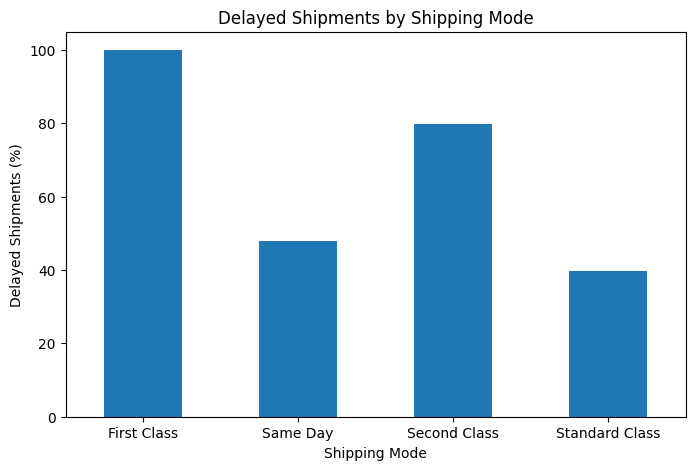

In [27]:
delay_rate = pd.crosstab(
    df['Shipping Mode'],
    df['Shipping Performance'],
    normalize='index'
) * 100

delay_rate['Delayed'].plot(kind='bar', figsize=(8, 5))

plt.title('Delayed Shipments by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Delayed Shipments (%)')
plt.xticks(rotation=0)
plt.show()

* Our conclusion: First Class has the highest delay percentage, while Standard Class has the lowest.

# REGIONAL DELIVERY PERFORMANCE

In [28]:
df.groupby('Order Region')['Shipping Performance'].value_counts()

Order Region    Shipping Performance
Canada          Delayed                   498
                Early                     291
                On Time                   170
Caribbean       Delayed                  4648
                Early                    2069
                                        ...  
West of USA     Early                    1936
                On Time                  1533
Western Europe  Delayed                 15863
                Early                    6402
                On Time                  4844
Name: count, Length: 69, dtype: int64

# CALCULATE REGIONAL DELAY RATES 

In [29]:
region_analysis = df.groupby('Order Region').agg(
    Total_Shipments=('Shipping Delay', 'count'),
    Delayed_Shipments=('Shipping Delay', lambda x: (x > 0).sum())
)

region_analysis['Delay Rate (%)'] = (
    region_analysis['Delayed_Shipments'] /
    region_analysis['Total_Shipments'] * 100
).round(2)

region_analysis.sort_values(
    'Delay Rate (%)', ascending=False
)

,Total_Shipments,Delayed_Shipments,Delay Rate (%)
Order Region,,,
Central Africa,1677,1018,60.70
Western Europe,27109,15863,58.52
South Asia,7731,4523,58.50
South of USA,4045,2350,58.10
Southeast Asia,9539,5531,57.98
East of USA,6915,4009,57.98
West Asia,6009,3455,57.50
East Africa,1852,1064,57.45
Eastern Europe,3920,2252,57.45


* Some important observations:
1. Central Africa: Highest delay rate at 60.70%.
2. Western Europe: 58.52%, with 15,863 delayed shipments.
3. South Asia: 58.50%, with 4,523 delayed shipments.
4. Central America: Has the highest shipment volume (28,341) and 57.25% delayed shipments.
5. Canada: Lowest delay rate at 51.93%.
* Business interpretation: Delays are widespread across regions. Central Africa has the highest delay percentage, while Central America has a
   particularly large number of delayed shipments because of its high shipment volume.

# SHIPPING PERFORMANCE BY MARKET 

In [30]:
df.groupby('Market')['Shipping Performance'].value_counts()

Market        Shipping Performance
Africa        Delayed                  6598
              Early                    2754
              On Time                  2262
Europe        Delayed                 28989
              Early                   12073
              On Time                  9190
LATAM         Delayed                 29420
              Early                   12539
              On Time                  9635
Pacific Asia  Delayed                 23649
              Early                    9869
              On Time                  7742
USCA          Delayed                 14744
              Early                    6131
              On Time                  4924
Name: count, dtype: int64

# CALCULATING MARKET-WISE DELAY RATES 

In [31]:
market_analysis = pd.crosstab(
    df['Market'],
    df['Shipping Performance'],
    normalize='index'
).mul(100).round(2)

market_analysis

Shipping Performance,Delayed,Early,On Time
Market,,,
Africa,56.81,23.71,19.48
Europe,57.69,24.02,18.29
LATAM,57.02,24.30,18.67
Pacific Asia,57.32,23.92,18.76
USCA,57.15,23.76,19.09


* Our findings:-
- Europe: Highest delay rate at 57.69%.
- Africa: Lowest delay rate at 56.81%.
- All five markets have very similar delay rates.
* The difference between the highest and lowest is less than 1 percentage point. This suggests that shipping delays are a widespread issue rather than a problem limited to one market.

# PRODUCT CATEGORY AND PROFITABILITY ANALYSIS

In [32]:
category_analysis = df.groupby('Category Name').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Profit_Ratio=('Order Item Profit Ratio', 'mean'),
    Items_Sold=('Order Item Quantity', 'sum')
).round(2)

category_analysis.sort_values('Total_Sales', ascending=False).head(10)

,Total_Sales,Average_Profit_Ratio,Items_Sold
Category Name,,,
Fishing,6929653.69,0.12,17325
Cleats,4431942.78,0.12,73734
Camping & Hiking,4118425.57,0.12,13729
Cardio Equipment,3694843.20,0.12,37587
Women's Apparel,3147800.00,0.12,62956
Water Sports,3113844.68,0.12,15540
Men's Footwear,2891757.66,0.12,22246
Indoor/Outdoor Games,2888993.91,0.12,57803
Shop By Sport,1309522.04,0.11,32726


* Key findings
1. Fishing generated the highest sales: 6,929,653.69.
2. Cleats ranked second with sales of 4,431,942.78.
3. Camping & Hiking ranked third with sales of 4,118,425.57.
4. The average profit ratio is approximately 0.12 (12%) for most of these categories.
5. Cleats sold the highest quantity, with 73,734 items.
* Business interpretation: Fishing leads in sales value, while Cleats leads in quantity sold. This shows that the category generating the most revenue isn't necessarily the category selling the most units.

# OVERALL BUSINESS KPI's

In [33]:
print("Total Sales:", round(df['Sales'].sum(), 2))
print("Total Orders:", df['Order Id'].nunique())
print("Total Products Sold:", df['Order Item Quantity'].sum())
print("Average Order Value:", round(
    df.groupby('Order Id')['Sales'].sum().mean(), 2
))
print("Total Delayed Shipments:", (df['Shipping Delay'] > 0).sum())

Total Sales: 36784735.01
Total Orders: 65752
Total Products Sold: 384079
Average Order Value: 559.45
Total Delayed Shipments: 103400


* One important distinction: We have 180,519 order-item records but 65,752 unique orders. That's why our order count is calculated using unique Order IDs.

# PREPARE THE DATASET FOR SQL

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "DataCoSupplyChainDataset.csv",
    encoding="latin1"
)

In [4]:
df['Shipping Delay'] = (
    df['Days for shipping (real)'] -
    df['Days for shipment (scheduled)']
)

df['Shipping Performance'] = np.where(
    df['Shipping Delay'] > 0, 'Delayed',
    np.where(df['Shipping Delay'] == 0, 'On Time', 'Early')
)

In [5]:
df[['Shipping Delay', 'Shipping Performance']].head()

,Shipping Delay,Shipping Performance
0,-1,Early
1,1,Delayed
2,0,On Time
3,-1,Early
4,-2,Early


In [6]:
sql_df = df[[
    'Order Id',
    'Order Item Id',
    'Sales',
    'Order Item Quantity',
    'Order Item Profit Ratio',
    'Category Name',
    'Product Name',
    'Shipping Mode',
    'Shipping Delay',
    'Shipping Performance',
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Market',
    'Order Region',
    'Order Country',
    'Order Status',
    'Customer Segment',
    'Department Name',
    'Delivery Status',
    'order date (DateOrders)',
    'shipping date (DateOrders)'
]].copy()

sql_df.to_csv('supply_chain_clean.csv', index=False)

In [7]:
check_df = pd.read_csv("supply_chain_clean.csv")
print(check_df.columns.tolist())
print(check_df.head(1).to_string())

['Order Id', 'Order Item Id', 'Sales', 'Order Item Quantity', 'Order Item Profit Ratio', 'Category Name', 'Product Name', 'Shipping Mode', 'Shipping Delay', 'Shipping Performance', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Market', 'Order Region', 'Order Country', 'Order Status', 'Customer Segment', 'Department Name', 'Delivery Status', 'order date (DateOrders)', 'shipping date (DateOrders)']
   Order Id  Order Item Id   Sales  Order Item Quantity  Order Item Profit Ratio   Category Name  Product Name   Shipping Mode  Shipping Delay Shipping Performance  Days for shipping (real)  Days for shipment (scheduled)        Market    Order Region Order Country Order Status Customer Segment Department Name   Delivery Status order date (DateOrders) shipping date (DateOrders)
0     77202         180517  327.75                    1                     0.29  Sporting Goods  Smart watch   Standard Class              -1                Early                         3               